## 1. Setup and GPU check

In [2]:
import os
from google.colab import drive
drive.mount('/content/drive')

PROJECT = '/content/drive/MyDrive/3D_project/pointnet2-dgcnn-shapenet-part'
assert os.path.isdir(PROJECT), 'Upload the project folder to Google Drive first (see the notes above).'
os.chdir(PROJECT)
for need in ['train.py', 'models.py', 'metrics.py', 'prepare_data.py', 'explain.py', 'aggregate.py', 'cache_small.npz']:
    assert os.path.exists(need), f'missing {need} in {PROJECT}'

def run(cmd):
    print('$', cmd, flush=True)
    get_ipython().system(cmd)

# training reads the data from the fast local disk; all results are written to Drive
run('cp -n cache_small.npz /content/cache_small.npz')
CACHE = '/content/cache_small.npz'

import torch
print('torch', torch.__version__, '| GPU available:', torch.cuda.is_available())
assert torch.cuda.is_available(), 'Switch the runtime to a T4 GPU: Runtime > Change runtime type'
print(torch.cuda.get_device_name(0))
run('nvidia-smi')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
$ cp -n cache_small.npz /content/cache_small.npz
cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead
torch 2.11.0+cu130 | GPU available: True
Tesla T4
$ nvidia-smi
Wed Nov  4 08:12:51 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+===========

## 2. Checks (about 1 minute)
Small tests that must pass before training: the data is in the right range, the train/validation/test splits do not overlap, the score function gives the right numbers on a hand-made example, and both models run forward and backward.

In [3]:
import numpy as np, torch, torch.nn.functional as F
from train import split_indices, NPARTS, OFFSETS, NUM_PARTS, NUM_CATS, CAT_NAMES
from models import PointNet2Seg, DGCNNSeg
from metrics import shape_iou, summarize

# 1. data
d = np.load(CACHE)
P, Y, C = d['points'], d['labels'].astype(np.int64), d['cats']
print('points', P.shape, '| labels', Y.shape, '| categories', len(np.unique(C)))
assert P.shape[1:] == (2048, 3)
assert np.isfinite(P).all()
assert np.linalg.norm(P, axis=2).max() <= 1.0001, 'points should be scaled to unit size'
lo = OFFSETS[C]
hi = lo + np.array(NPARTS)[C]
assert ((Y >= lo[:, None]) & (Y < hi[:, None])).all(), 'every label must belong to its own category'
print('OK data: finite, scaled to unit size, labels inside each category range')
print({CAT_NAMES[c]: int((C == c).sum()) for c in range(NUM_CATS)})

# 2. splits
for seed in (0, 1, 2):
    tr, va, te = split_indices(C, seed)
    assert not (set(tr) & set(va)) and not (set(tr) & set(te)) and not (set(va) & set(te)), 'splits overlap'
    assert len(tr) + len(va) + len(te) == len(C)
    print(f'OK split seed {seed}: train {len(tr)}, val {len(va)}, test {len(te)}')

# 3. metric on a hand-made example: parts 0 and 1; IoU part 0 = 1/2, part 1 = 2/3
gt = np.array([0, 0, 1, 1]); pred = np.array([0, 1, 1, 1])
assert abs(shape_iou(pred, gt, 0, 2)[0] - (0.5 + 2 / 3) / 2) < 1e-9
assert shape_iou(gt, gt, 0, 2)[0] == 1.0
print('OK metric')

# 4. models: forward and backward pass on 2 real shapes
dev = torch.device('cuda')
x = torch.from_numpy(P[:2]).to(dev)
c = torch.from_numpy(C[:2]).long().to(dev)
y = torch.from_numpy(Y[:2]).to(dev)
onehot = F.one_hot(c, NUM_CATS).float()
for name, m in [('PointNet++', PointNet2Seg(NUM_PARTS, NUM_CATS)), ('DGCNN', DGCNNSeg(NUM_PARTS, NUM_CATS))]:
    m = m.to(dev).train()
    out = m(x, onehot)
    assert out.shape == (2, 2048, NUM_PARTS)
    loss = F.cross_entropy(out.reshape(-1, NUM_PARTS), y.reshape(-1))
    loss.backward()
    assert torch.isfinite(loss) and all(p.grad is None or torch.isfinite(p.grad).all() for p in m.parameters())
    print('OK model', name, '| output', tuple(out.shape), '| loss', round(loss.item(), 3))
print('ALL CHECKS PASSED')

points (2602, 2048, 3) | labels (2602, 2048) | categories 16
OK data: finite, scaled to unit size, labels inside each category range
{'Airplane': 200, 'Bag': 76, 'Cap': 55, 'Car': 200, 'Chair': 200, 'Earphone': 69, 'Guitar': 200, 'Knife': 200, 'Lamp': 200, 'Laptop': 200, 'Motorbike': 200, 'Mug': 184, 'Pistol': 200, 'Rocket': 66, 'Skateboard': 152, 'Table': 200}
OK split seed 0: train 2079, val 260, test 263
OK split seed 1: train 2079, val 260, test 263
OK split seed 2: train 2079, val 260, test 263
OK metric
OK model PointNet++ | output (2, 2048, 50) | loss 4.245
OK model DGCNN | output (2, 2048, 50) | loss 4.088
ALL CHECKS PASSED


## 3. Training: 3 seeds x 2 models
Same data, settings and seed for both models in each pair. If the session stops, run this cell again: finished runs are only re-tested, and unfinished runs continue from their last epoch.

In [4]:
SEEDS = [0, 1, 2]
MODELS = [('pointnet2', 'pn2'), ('dgcnn', 'dgcn')]
for seed in SEEDS:
    for model, tag in MODELS:
        run(f'python train.py --model {model} --cache {CACHE} --epochs 30 --batch_size 16 '
            f'--seed {seed} --out runs/{tag}_s{seed} --resume')

$ python train.py --model pointnet2 --cache /content/cache_small.npz --epochs 30 --batch_size 16 --seed 0 --out runs/pn2_s0 --resume
device=cuda  shapes: train 2079  val 260  test 263  points/shape 2048
parameters: 1.39M
epoch   1  loss 1.9439  val inst-mIoU 0.4953  class-mIoU 0.4761  (26s)
epoch   2  loss 0.8237  val inst-mIoU 0.5813  class-mIoU 0.5608  (26s)
epoch   3  loss 0.5062  val inst-mIoU 0.6374  class-mIoU 0.6228  (26s)
epoch   4  loss 0.4185  val inst-mIoU 0.6946  class-mIoU 0.6777  (27s)
epoch   5  loss 0.3744  val inst-mIoU 0.7049  class-mIoU 0.6943  (27s)
epoch   6  loss 0.3282  val inst-mIoU 0.7389  class-mIoU 0.7314  (26s)
epoch   7  loss 0.3132  val inst-mIoU 0.7575  class-mIoU 0.7445  (27s)
epoch   8  loss 0.3002  val inst-mIoU 0.7494  class-mIoU 0.7448  (27s)
epoch   9  loss 0.2720  val inst-mIoU 0.7708  class-mIoU 0.7680  (26s)
epoch  10  loss 0.2602  val inst-mIoU 0.7554  class-mIoU 0.7357  (26s)
epoch  11  loss 0.2539  val inst-mIoU 0.7397  class-mIoU 0.7241  (26s

## 4. Results table (mean and standard deviation over seeds)

In [5]:
run('python aggregate.py --runs runs --epochs 30 --out results_table.md')

$ python aggregate.py --runs runs --epochs 30 --out results_table.md
## Per run

| run | model | seed | instance mIoU | class mIoU |
|---|---|---|---|---|
| dgcn_s0 | dgcnn | 0 | 0.8140 | 0.7958 |
| dgcn_s1 | dgcnn | 1 | 0.8066 | 0.7942 |
| dgcn_s2 | dgcnn | 2 | 0.8132 | 0.8027 |
| pn2_s0 | pointnet2 | 0 | 0.8143 | 0.7984 |
| pn2_s1 | pointnet2 | 1 | 0.8058 | 0.7950 |
| pn2_s2 | pointnet2 | 2 | 0.8097 | 0.8010 |

## Mean ± standard deviation over seeds

| model | seeds | instance mIoU | class mIoU |
|---|---|---|---|
| dgcnn | 0,1,2 | 0.8113 ± 0.0041 | 0.7975 ± 0.0045 |
| pointnet2 | 0,1,2 | 0.8099 ± 0.0043 | 0.7981 ± 0.0030 |

## Per category (mean ± std over seeds; small categories are very noisy)

| category | dgcnn | pointnet2 |
|---|---|---|
| Airplane | 0.7981 ± 0.0185 | 0.7825 ± 0.0308 |
| Bag | 0.8180 ± 0.0417 | 0.8498 ± 0.0427 |
| Cap | 0.8195 ± 0.0730 | 0.7830 ± 0.0789 |
| Car | 0.7147 ± 0.0205 | 0.7112 ± 0.0283 |
| Chair | 0.8625 ± 0.0136 | 0.8650 ± 0.0112 |
| Earphone | 0.7

## 5. Saliency figures and statistics
For each model and seed: 200 test shapes, with SmoothGrad and neighbour smoothing. The summary lines give the saliency of correct and wrong points and the boundary test. Figures are saved for the first 8 shapes of seed 0. Then the same shapes without smoothing (seed 0) for comparison. Logs are saved in `logs/`.

In [6]:
os.makedirs('logs', exist_ok=True)
for seed in SEEDS:
    for model, tag in MODELS:
        n_figs = 8 if seed == 0 else 0
        run(f'python explain.py --model {model} --cache {CACHE} --ckpt runs/{tag}_s{seed}/best.pt '
            f'--seed {seed} --n_shapes 200 --n_figs {n_figs} --out figs/{tag}_smoothed_s{seed} '
            f'| tee logs/explain_{tag}_smoothed_s{seed}.txt')

# raw gradients (no smoothing), seed 0 only, same shapes as above
for model, tag in MODELS:
    run(f'python explain.py --model {model} --cache {CACHE} --ckpt runs/{tag}_s0/best.pt '
        f'--seed 0 --n_shapes 200 --n_figs 8 --noise_samples 1 --smooth_k 1 --out figs/{tag}_raw_s0 '
        f'| tee logs/explain_{tag}_raw_s0.txt')

$ python explain.py --model pointnet2 --cache /content/cache_small.npz --ckpt runs/pn2_s0/best.pt --seed 0 --n_shapes 200 --n_figs 8 --out figs/pn2_smoothed_s0 | tee logs/explain_pn2_smoothed_s0.txt
Saved 8 figures to figs/pn2_smoothed_s0/
boundary test over 195 of 200 shapes (shapes with a clear boundary): 16% of points are boundary points; mean relative saliency boundary 1.03 vs interior 1.01; boundary/interior ratio per shape: mean 1.03, median 0.94, above 1 in 78 of 195 shapes
mean relative saliency: correctly predicted points 1.00, wrongly predicted points 0.95  (over 200 shapes; 1.0 = shape average)
$ python explain.py --model dgcnn --cache /content/cache_small.npz --ckpt runs/dgcn_s0/best.pt --seed 0 --n_shapes 200 --n_figs 8 --out figs/dgcn_smoothed_s0 | tee logs/explain_dgcn_smoothed_s0.txt
Saved 8 figures to figs/dgcn_smoothed_s0/
boundary test over 195 of 200 shapes (shapes with a clear boundary): 16% of points are boundary points; mean relative saliency boundary 1.16 vs int

## 6. All saliency summary lines in one place

In [7]:
run('grep -H -E "mean relative|boundary test" logs/*.txt')

$ grep -H -E "mean relative|boundary test" logs/*.txt
logs/explain_dgcn_raw_s0.txt:boundary test over 195 of 200 shapes (shapes with a clear boundary): 16% of points are boundary points; mean relative saliency boundary 1.23 vs interior 0.99; boundary/interior ratio per shape: mean 1.26, median 1.15, above 1 in 135 of 195 shapes
logs/explain_dgcn_raw_s0.txt:mean relative saliency: correctly predicted points 0.99, wrongly predicted points 1.10  (over 200 shapes; 1.0 = shape average)
logs/explain_dgcn_smoothed_s0.txt:boundary test over 195 of 200 shapes (shapes with a clear boundary): 16% of points are boundary points; mean relative saliency boundary 1.16 vs interior 0.99; boundary/interior ratio per shape: mean 1.18, median 1.12, above 1 in 129 of 195 shapes
logs/explain_dgcn_smoothed_s0.txt:mean relative saliency: correctly predicted points 1.00, wrongly predicted points 1.07  (over 200 shapes; 1.0 = shape average)
logs/explain_dgcn_smoothed_s1.txt:boundary test over 191 of 200 shapes (

## 7. Look at a few figures

figs/pn2_smoothed_s0


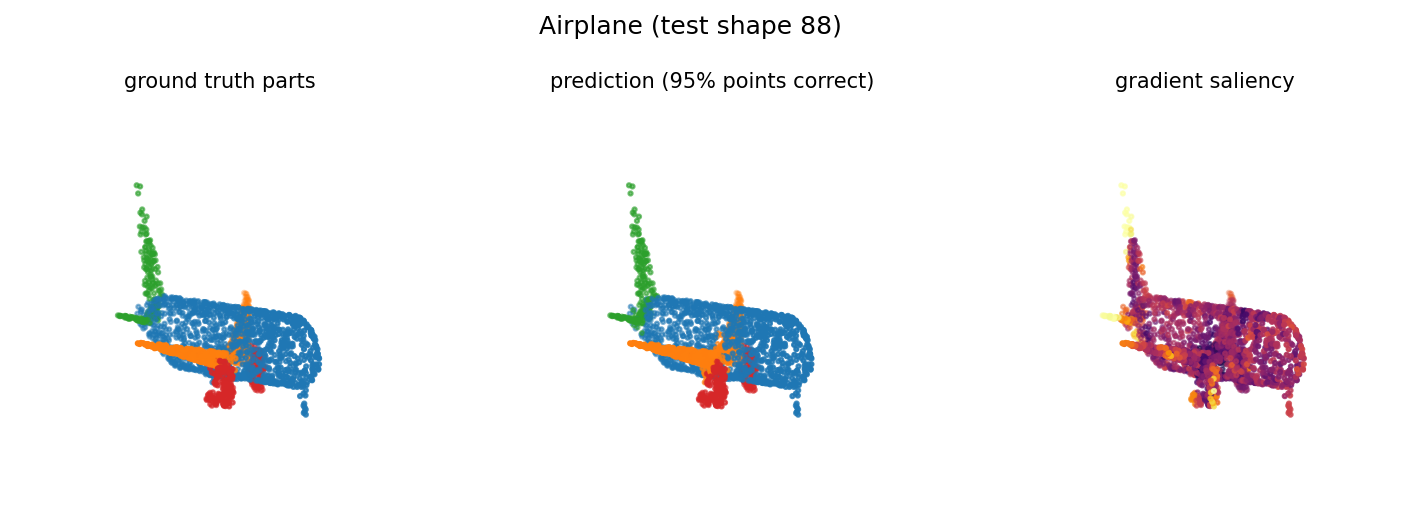

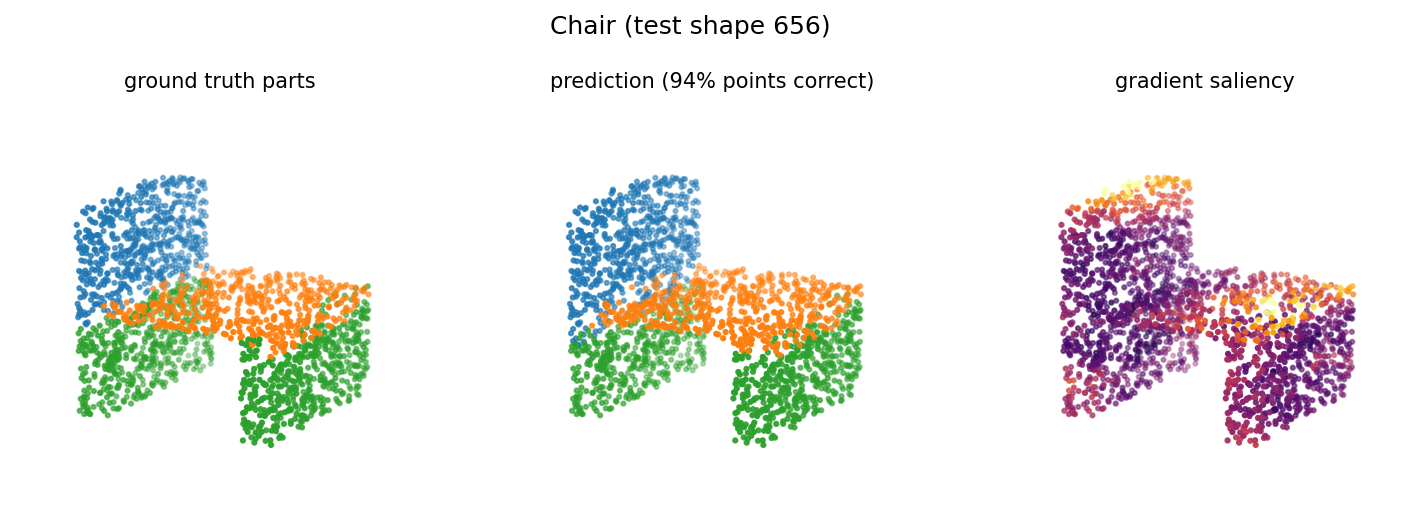

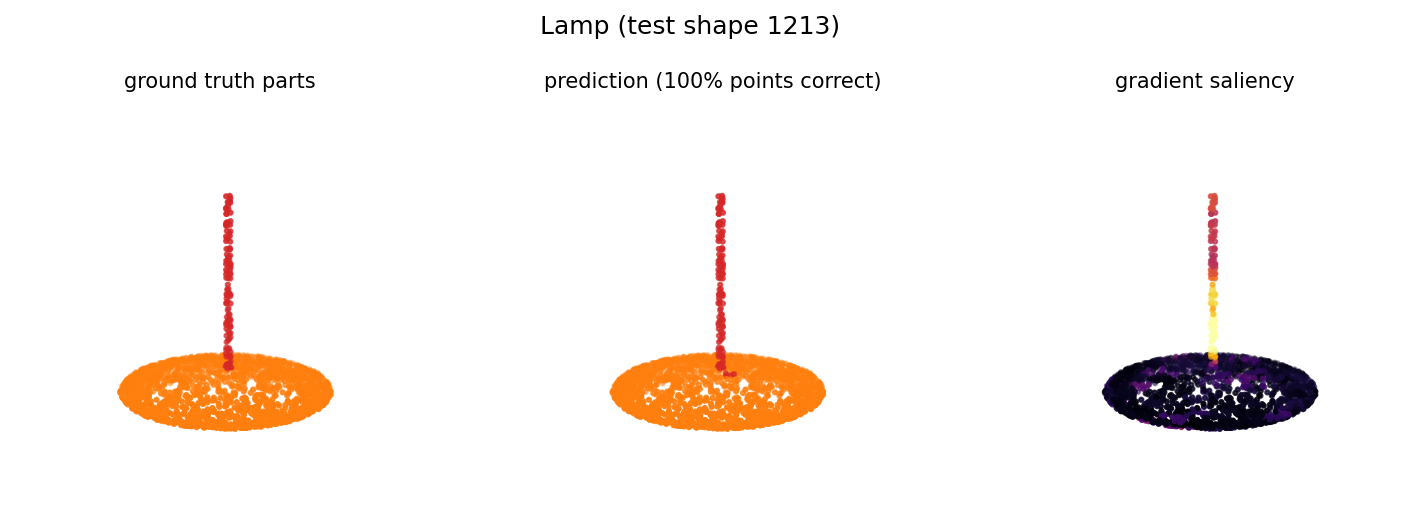

figs/dgcn_smoothed_s0


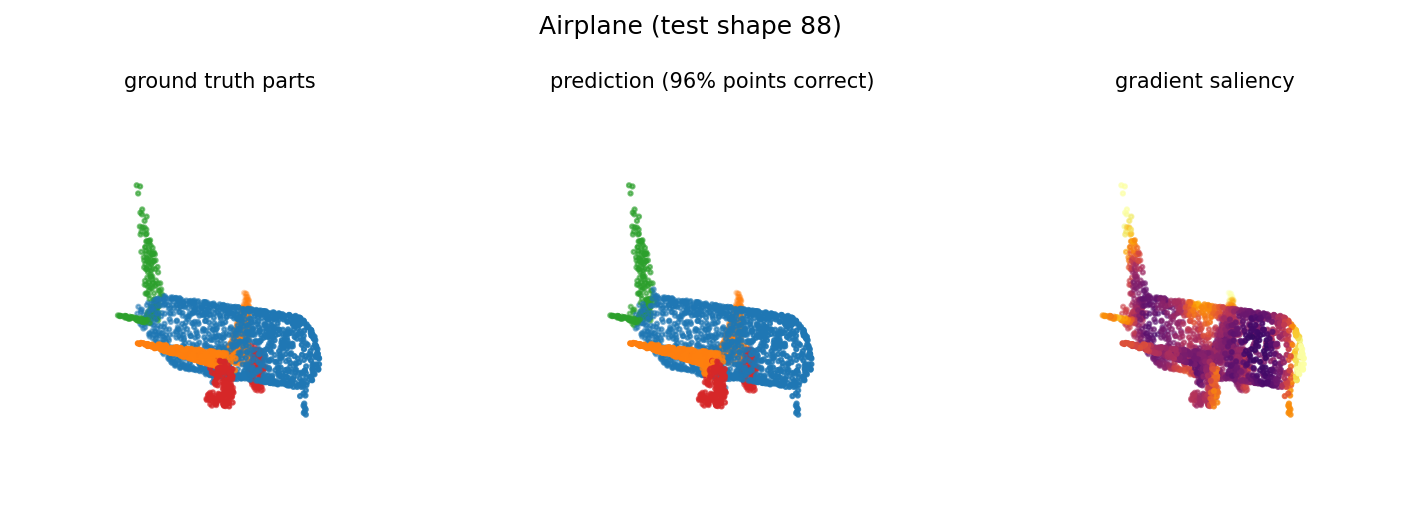

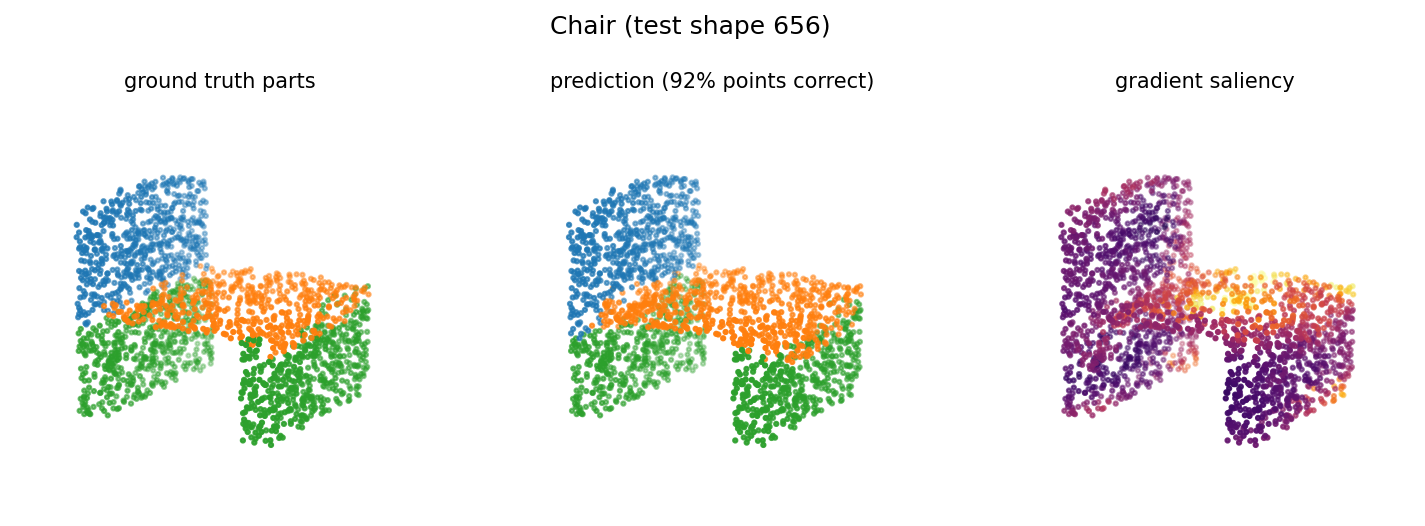

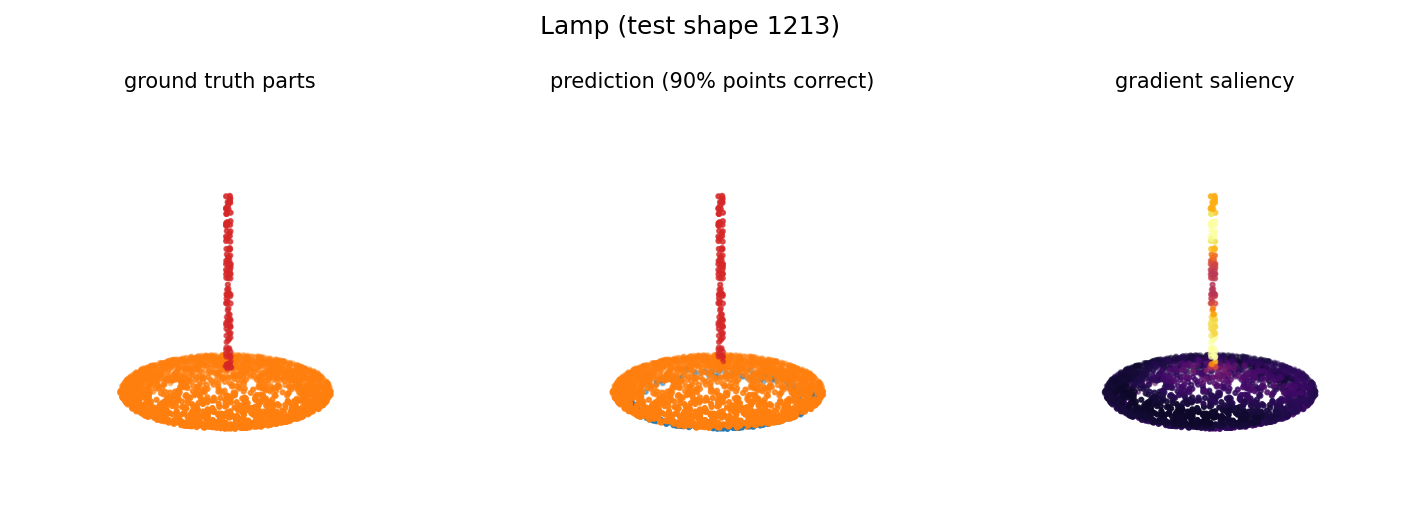

In [8]:
import glob
from IPython.display import Image, display
for folder in ['figs/pn2_smoothed_s0', 'figs/dgcn_smoothed_s0']:
    print(folder)
    for f in sorted(glob.glob(folder + '/*.png'))[:3]:
        display(Image(f))

## 8. Download a bundle of the results (optional)
Everything is already saved in your Drive folder. This makes one zip without the large model files. After the run, use **File > Download > Download .ipynb** to keep this notebook with all its printed outputs.

In [9]:
run('zip -qr results_bundle.zip runs figs logs results_table.md -x "*.pt"')
from google.colab import files
files.download('results_bundle.zip')

$ zip -qr results_bundle.zip runs figs logs results_table.md -x "*.pt"


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>